In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
ds=pd.read_csv("D:\\AmericanBankcruptcy\\artifacts\\data_ingestion\\american_bankruptcy.csv")


In [3]:
ds.head()

,company_name,status_label,year,X1,X2,X3,X4,X5,X6,X7,...,X9,X10,X11,X12,X13,X14,X15,X16,X17,X18
0,C_1,alive,1999,511.267,833.107,18.373,89.031,336.018,35.163,128.348,...,1024.333,740.998,180.447,70.658,191.226,163.816,201.026,1024.333,401.483,935.302
1,C_1,alive,2000,485.856,713.811,18.577,64.367,320.590,18.531,115.187,...,874.255,701.854,179.987,45.790,160.444,125.392,204.065,874.255,361.642,809.888
2,C_1,alive,2001,436.656,526.477,22.496,27.207,286.588,-58.939,77.528,...,638.721,710.199,217.699,4.711,112.244,150.464,139.603,638.721,399.964,611.514
3,C_1,alive,2002,396.412,496.747,27.172,30.745,259.954,-12.410,66.322,...,606.337,686.621,164.658,3.573,109.590,203.575,124.106,606.337,391.633,575.592
4,C_1,alive,2003,432.204,523.302,26.680,47.491,247.245,3.504,104.661,...,651.958,709.292,248.666,20.811,128.656,131.261,131.884,651.958,407.608,604.467


In [4]:
ds=ds.drop(columns=["company_name"])

In [5]:
ds=ds.rename(columns=
{
"X1"	:"Current assets",
"X2"	:"Cost of goods sold",
"X3"	:"Depreciation and amortization",
"X4"	:"EBITDA",
"X5"	:"Inventory" ,
"X6"	:"Net Income",
"X7"	:"Total Receivables",
"X8"	:"Market value",
"X9"	:"Net sales",
"X10"	:"Total assets",
"X11"	:"Total Long-term debt",
"X12"	:"EBIT",
"X13"	:"Gross Profit",
"X14"	:"Total Current Liabilities",
"X15"	:"Retained Earnings" ,
"X16"	:"Total Revenue",
"X17"	:"Total Liabilities",
"X18"	:"Total Operating Expenses"
 }
)

In [6]:
ds.info()

<class 'pandas.DataFrame'>
RangeIndex: 78682 entries, 0 to 78681
Data columns (total 20 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   status_label                   78682 non-null  str    
 1   year                           78682 non-null  int64  
 2   Current assets                 78682 non-null  float64
 3   Cost of goods sold             78682 non-null  float64
 4   Depreciation and amortization  78682 non-null  float64
 5   EBITDA                         78682 non-null  float64
 6   Inventory                      78682 non-null  float64
 7   Net Income                     78682 non-null  float64
 8   Total Receivables              78682 non-null  float64
 9   Market value                   78682 non-null  float64
 10  Net sales                      78682 non-null  float64
 11  Total assets                   78682 non-null  float64
 12  Total Long-term debt           78682 non-null  float64
 1

In [7]:
ds.columns = ds.columns.str.replace(" ", "")

In [8]:
ds.describe().T

,count,mean,std,min,25%,50%,75%,max
year,78682.0,2007.506317,5.742768,1999.0000,2002.00000,2007.00000,2012.00000,2018.00
Currentassets,78682.0,880.362485,3928.564794,-7.7600,18.92400,100.44950,431.52675,169662.00
Costofgoodssold,78682.0,1594.529029,8930.484664,-366.6450,17.03825,103.66100,634.54800,374623.00
Depreciationandamortization,78682.0,121.234256,652.376804,0.0000,1.19200,7.92950,47.97175,28430.00
EBITDA,78682.0,376.759424,2012.023142,-21913.0000,-0.81100,15.03450,139.65525,81730.00
Inventory,78682.0,201.605717,1060.766096,0.0000,0.00000,7.02300,74.74725,62567.00
NetIncome,78682.0,129.382453,1265.532022,-98696.0000,-7.41575,1.61600,40.14425,104821.00
TotalReceivables,78682.0,286.832743,1335.978571,-0.0060,3.28125,22.82000,131.58050,65812.00
Marketvalue,78682.0,3414.354610,18414.103647,0.0001,34.98000,227.51185,1244.88995,1073390.54
Netsales,78682.0,2364.019706,11950.068842,-1964.9990,27.54850,186.59850,1046.40250,511729.00


In [9]:
ds.columns.values

<ArrowStringArray>
[               'status_label',                        'year',
               'Currentassets',             'Costofgoodssold',
 'Depreciationandamortization',                      'EBITDA',
                   'Inventory',                   'NetIncome',
            'TotalReceivables',                 'Marketvalue',
                    'Netsales',                 'Totalassets',
          'TotalLong-termdebt',                        'EBIT',
                 'GrossProfit',     'TotalCurrentLiabilities',
            'RetainedEarnings',                'TotalRevenue',
            'TotalLiabilities',      'TotalOperatingExpenses']
Length: 20, dtype: str

In [10]:
ds.select_dtypes(include=['str']).columns


Index(['status_label'], dtype='str')

In [11]:
ds["status_label"].value_counts()

status_label
alive     73462
failed     5220
Name: count, dtype: int64

In [12]:
ds.isnull().sum()

status_label                   0
year                           0
Currentassets                  0
Costofgoodssold                0
Depreciationandamortization    0
EBITDA                         0
Inventory                      0
NetIncome                      0
TotalReceivables               0
Marketvalue                    0
Netsales                       0
Totalassets                    0
TotalLong-termdebt             0
EBIT                           0
GrossProfit                    0
TotalCurrentLiabilities        0
RetainedEarnings               0
TotalRevenue                   0
TotalLiabilities               0
TotalOperatingExpenses         0
dtype: int64

In [13]:
ds.duplicated().sum()

np.int64(0)

In [14]:
Q1 = ds.quantile(0.25, numeric_only = True)
Q3 = ds.quantile(0.75, numeric_only = True)
IQR = Q3 - Q1
print(IQR)

year                             10.00000
Currentassets                   412.60275
Costofgoodssold                 617.50975
Depreciationandamortization      46.77975
EBITDA                          140.46625
Inventory                        74.74725
NetIncome                        47.56000
TotalReceivables                128.29925
Marketvalue                    1209.90995
Netsales                       1018.85400
Totalassets                    1134.00125
TotalLong-termdebt              248.76075
EBIT                             90.38600
GrossProfit                     335.55300
TotalCurrentLiabilities         213.92775
RetainedEarnings                214.35275
TotalRevenue                   1018.85400
TotalLiabilities                616.48900
TotalOperatingExpenses          842.64975
dtype: float64


In [15]:
min=Q1 - 1.5 * IQR
max=Q3 + 1.5 * IQR

In [16]:
numeric=ds.select_dtypes(include=['int64','float64'])
numeric

,year,Currentassets,Costofgoodssold,Depreciationandamortization,EBITDA,Inventory,NetIncome,TotalReceivables,Marketvalue,Netsales,Totalassets,TotalLong-termdebt,EBIT,GrossProfit,TotalCurrentLiabilities,RetainedEarnings,TotalRevenue,TotalLiabilities,TotalOperatingExpenses
0,1999,511.267,833.107,18.373,89.031,336.018,35.163,128.348,372.7519,1024.333,740.998,180.447,70.658,191.226,163.816,201.026,1024.333,401.483,935.302
1,2000,485.856,713.811,18.577,64.367,320.590,18.531,115.187,377.1180,874.255,701.854,179.987,45.790,160.444,125.392,204.065,874.255,361.642,809.888
2,2001,436.656,526.477,22.496,27.207,286.588,-58.939,77.528,364.5928,638.721,710.199,217.699,4.711,112.244,150.464,139.603,638.721,399.964,611.514
3,2002,396.412,496.747,27.172,30.745,259.954,-12.410,66.322,143.3295,606.337,686.621,164.658,3.573,109.590,203.575,124.106,606.337,391.633,575.592
4,2003,432.204,523.302,26.680,47.491,247.245,3.504,104.661,308.9071,651.958,709.292,248.666,20.811,128.656,131.261,131.884,651.958,407.608,604.467
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
78677,2014,233.211,43.338,14.094,45.615,3.376,25.261,22.846,756.4827,104.223,1099.101,184.666,31.521,60.885,28.197,28.095,104.223,225.887,58.608
78678,2015,105.559,59.184,42.592,202.133,2.288,129.688,54.611,527.5750,291.153,1865.926,770.103,159.541,231.969,88.128,157.783,291.153,880.327,89.020
78679,2016,63.971,69.074,65.057,79.051,2.581,-1.442,42.467,578.8868,169.858,1746.235,683.985,13.994,100.784,85.765,156.341,169.858,770.233,90.807
78680,2017,135.207,66.527,65.330,69.171,2.013,-20.401,27.217,412.6241,161.884,1736.110,694.035,3.841,95.357,82.010,135.941,161.884,776.697,92.713


In [18]:
numeric_cols = ds.select_dtypes(include="number").columns
outlier_mask = ds[numeric_cols].lt(min[numeric_cols]) | ds[numeric_cols].gt(max[numeric_cols])

ds = ds.loc[~outlier_mask.any(axis=1)].copy()
ds["status_label"].value_counts()

status_label
alive     48787
failed     3474
Name: count, dtype: int64

In [22]:
numeric.clip(min, max, axis=1)

,year,Currentassets,Costofgoodssold,Depreciationandamortization,EBITDA,Inventory,NetIncome,TotalReceivables,Marketvalue,Netsales,Totalassets,TotalLong-termdebt,EBIT,GrossProfit,TotalCurrentLiabilities,RetainedEarnings,TotalRevenue,TotalLiabilities,TotalOperatingExpenses
0,1999,511.267,833.107,18.373,89.031,186.868125,35.16300,128.348,372.7519,1024.333,740.998,180.447000,70.658,191.226,163.816,201.026,1024.333,401.483,935.302
1,2000,485.856,713.811,18.577,64.367,186.868125,18.53100,115.187,377.1180,874.255,701.854,179.987000,45.790,160.444,125.392,204.065,874.255,361.642,809.888
2,2001,436.656,526.477,22.496,27.207,186.868125,-58.93900,77.528,364.5928,638.721,710.199,217.699000,4.711,112.244,150.464,139.603,638.721,399.964,611.514
3,2002,396.412,496.747,27.172,30.745,186.868125,-12.41000,66.322,143.3295,606.337,686.621,164.658000,3.573,109.590,203.575,124.106,606.337,391.633,575.592
4,2003,432.204,523.302,26.680,47.491,186.868125,3.50400,104.661,308.9071,651.958,709.292,248.666000,20.811,128.656,131.261,131.884,651.958,407.608,604.467
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
78677,2014,233.211,43.338,14.094,45.615,3.376000,25.26100,22.846,756.4827,104.223,1099.101,184.666000,31.521,60.885,28.197,28.095,104.223,225.887,58.608
78678,2015,105.559,59.184,42.592,202.133,2.288000,111.48425,54.611,527.5750,291.153,1865.926,621.901875,159.541,231.969,88.128,157.783,291.153,880.327,89.020
78679,2016,63.971,69.074,65.057,79.051,2.581000,-1.44200,42.467,578.8868,169.858,1746.235,621.901875,13.994,100.784,85.765,156.341,169.858,770.233,90.807
78680,2017,135.207,66.527,65.330,69.171,2.013000,-20.40100,27.217,412.6241,161.884,1736.110,621.901875,3.841,95.357,82.010,135.941,161.884,776.697,92.713


In [46]:
numeric.

,year,Currentassets,Costofgoodssold,Depreciationandamortization,EBITDA,Inventory,NetIncome,TotalReceivables,Marketvalue,Netsales,Totalassets,TotalLong-termdebt,EBIT,GrossProfit,TotalCurrentLiabilities,RetainedEarnings,TotalRevenue,TotalLiabilities,TotalOperatingExpenses
31,1999,9.757,19.796,0.667,-0.265,5.494,-2.207,3.924,3.2449,29.370,13.986,5.974,-0.932,9.574,2.804,-6.375,29.370,8.778,29.635
32,2000,7.884,16.506,0.700,0.672,4.078,-0.808,3.244,4.5428,25.367,11.608,4.875,-0.028,8.861,2.278,-7.184,25.367,7.153,24.695
33,2001,6.494,15.700,0.761,0.381,3.488,-1.738,2.677,2.9667,24.051,8.635,3.873,-0.380,8.351,2.045,-8.922,24.051,5.918,23.670
34,2002,5.938,12.919,0.355,0.711,2.816,0.084,2.465,1.5761,20.087,7.850,2.546,0.356,7.168,2.481,-8.816,20.087,5.027,19.376
35,2004,5.807,12.018,0.160,1.614,2.704,1.345,2.504,13.9065,19.833,6.245,0.222,1.454,7.815,3.222,-8.974,19.833,3.580,18.219
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
78662,2014,58.314,1.833,0.656,-45.934,5.488,-48.205,0.470,17.0644,2.828,59.500,0.000,-46.590,0.995,9.143,-199.926,2.828,9.322,48.762
78663,2015,21.381,4.972,0.486,-33.631,1.025,-35.161,0.040,0.1996,1.316,21.782,0.003,-34.117,-3.656,3.521,-235.087,1.316,3.524,34.947
78664,2016,9.049,1.077,0.190,-12.783,0.213,-13.116,0.030,0.1309,0.545,9.198,0.000,-12.973,-0.532,2.391,-248.203,0.545,2.408,13.328
78665,2017,3.369,0.208,0.057,-10.647,0.000,-10.890,0.040,0.2231,0.053,3.466,0.000,-10.704,-0.155,7.152,-259.121,0.053,7.181,10.700


In [18]:
outlier_mask = numeric.lt(min[numeric.columns]) | numeric.gt(max[numeric.columns])

outlier_counts = outlier_mask.sum().sort_values(ascending=False)
print("Outlier count per column:")
display(outlier_counts)

outlier_rows = numeric[outlier_mask.any(axis=1)]
display(outlier_rows)

Outlier count per column:


RetainedEarnings               17867
NetIncome                      17004
EBIT                           13251
TotalLong-termdebt             12641
Inventory                      12435
TotalLiabilities               12366
EBITDA                         12218
TotalCurrentLiabilities        11781
Costofgoodssold                11594
Totalassets                    11521
Depreciationandamortization    11475
Marketvalue                    11409
GrossProfit                    11306
TotalReceivables               11237
Netsales                       11225
TotalRevenue                   11225
TotalOperatingExpenses         11214
Currentassets                  10975
year                               0
dtype: int64

,year,Currentassets,Costofgoodssold,Depreciationandamortization,EBITDA,Inventory,NetIncome,TotalReceivables,Marketvalue,Netsales,Totalassets,TotalLong-termdebt,EBIT,GrossProfit,TotalCurrentLiabilities,RetainedEarnings,TotalRevenue,TotalLiabilities,TotalOperatingExpenses
0,1999,511.267,833.107,18.373,89.031,336.018,35.163,128.348,372.7519,1024.333,740.998,180.447,70.658,191.226,163.816,201.026,1024.333,401.483,935.302
1,2000,485.856,713.811,18.577,64.367,320.590,18.531,115.187,377.1180,874.255,701.854,179.987,45.790,160.444,125.392,204.065,874.255,361.642,809.888
2,2001,436.656,526.477,22.496,27.207,286.588,-58.939,77.528,364.5928,638.721,710.199,217.699,4.711,112.244,150.464,139.603,638.721,399.964,611.514
3,2002,396.412,496.747,27.172,30.745,259.954,-12.410,66.322,143.3295,606.337,686.621,164.658,3.573,109.590,203.575,124.106,606.337,391.633,575.592
4,2003,432.204,523.302,26.680,47.491,247.245,3.504,104.661,308.9071,651.958,709.292,248.666,20.811,128.656,131.261,131.884,651.958,407.608,604.467
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
78676,2018,931.600,1475.900,82.500,619.000,280.300,434.900,340.300,7543.5153,2731.700,2810.200,1409.500,536.500,1255.800,520.800,650.100,2731.700,2156.200,2112.700
78678,2015,105.559,59.184,42.592,202.133,2.288,129.688,54.611,527.5750,291.153,1865.926,770.103,159.541,231.969,88.128,157.783,291.153,880.327,89.020
78679,2016,63.971,69.074,65.057,79.051,2.581,-1.442,42.467,578.8868,169.858,1746.235,683.985,13.994,100.784,85.765,156.341,169.858,770.233,90.807
78680,2017,135.207,66.527,65.330,69.171,2.013,-20.401,27.217,412.6241,161.884,1736.110,694.035,3.841,95.357,82.010,135.941,161.884,776.697,92.713


,year,Currentassets,Costofgoodssold,Depreciationandamortization,EBITDA,Inventory,NetIncome,TotalReceivables,Marketvalue,Netsales,Totalassets,TotalLong-termdebt,EBIT,GrossProfit,TotalCurrentLiabilities,RetainedEarnings,TotalRevenue,TotalLiabilities,TotalOperatingExpenses
year,1.000000,0.096764,0.065320,0.078040,0.082694,0.073918,0.063232,0.082141,0.080689,0.075471,0.100649,0.121160,0.077256,0.084388,0.085043,0.052765,0.075471,0.104300,0.070588
Currentassets,0.096764,1.000000,0.660564,0.659173,0.812872,0.638698,0.657366,0.851945,0.826568,0.758712,0.824172,0.641522,0.806540,0.839140,0.903493,0.549777,0.758712,0.794479,0.713187
Costofgoodssold,0.065320,0.660564,1.000000,0.601328,0.674880,0.780846,0.517079,0.662863,0.556610,0.975963,0.681138,0.479374,0.646028,0.723855,0.784213,0.593223,0.975963,0.657386,0.988994
Depreciationandamortization,0.078040,0.659173,0.601328,1.000000,0.853222,0.426229,0.534297,0.696474,0.668160,0.700824,0.911330,0.781753,0.712093,0.796021,0.752106,0.588563,0.700824,0.877051,0.639004
EBITDA,0.082694,0.812872,0.674880,0.853222,1.000000,0.512667,0.766148,0.779820,0.859896,0.796124,0.916728,0.730642,0.973745,0.923711,0.835342,0.674287,0.796124,0.865836,0.719960
Inventory,0.073918,0.638698,0.780846,0.426229,0.512667,1.000000,0.395436,0.503019,0.483074,0.791135,0.553202,0.415740,0.504091,0.657215,0.719630,0.436993,0.791135,0.557678,0.808342
NetIncome,0.063232,0.657366,0.517079,0.534297,0.766148,0.395436,1.000000,0.588943,0.714706,0.606444,0.646947,0.434078,0.798147,0.696554,0.637441,0.628653,0.606444,0.587707,0.547576
TotalReceivables,0.082141,0.851945,0.662863,0.696474,0.779820,0.503019,0.588943,1.000000,0.684549,0.726521,0.806388,0.645599,0.745765,0.731790,0.872734,0.570250,0.726521,0.807136,0.682650
Marketvalue,0.080689,0.826568,0.556610,0.668160,0.859896,0.483074,0.714706,0.684549,1.000000,0.685420,0.789200,0.576519,0.865917,0.853052,0.762850,0.629782,0.685420,0.712536,0.620050
Netsales,0.075471,0.758712,0.975963,0.700824,0.796124,0.791135,0.606444,0.726521,0.685420,1.000000,0.784902,0.581507,0.765814,0.856822,0.858866,0.635692,1.000000,0.754276,0.993149


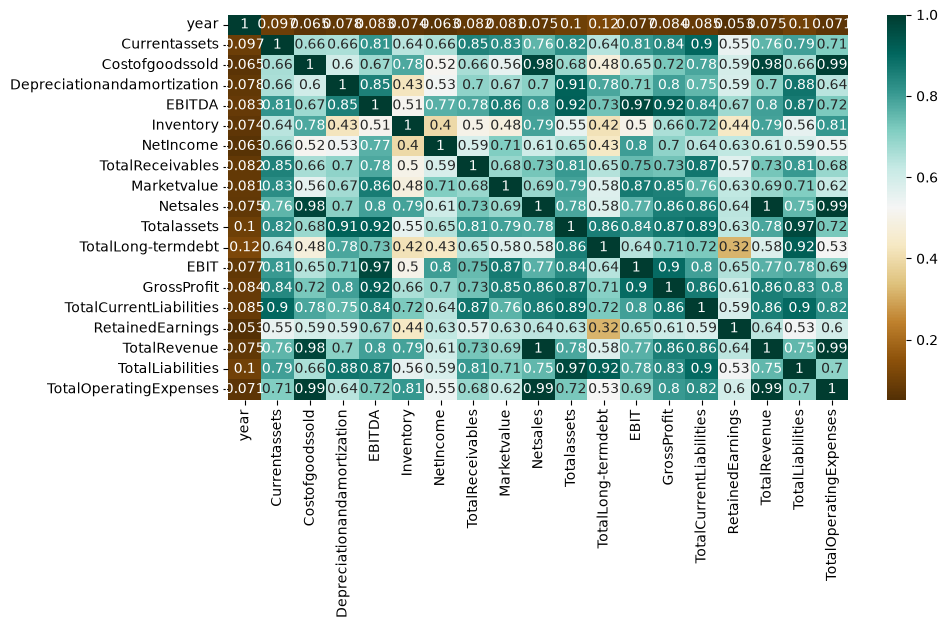

In [19]:
plt.figure(figsize=(10,5))
c = numeric.corr()
sns.heatmap(c,cmap="BrBG",annot=True)
c

In [21]:
ds

,status_label,year,Currentassets,Costofgoodssold,Depreciationandamortization,EBITDA,Inventory,NetIncome,TotalReceivables,Marketvalue,Netsales,Totalassets,TotalLong-termdebt,EBIT,GrossProfit,TotalCurrentLiabilities,RetainedEarnings,TotalRevenue,TotalLiabilities,TotalOperatingExpenses
0,alive,1999,511.267,833.107,18.373,89.031,336.018,35.163,128.348,372.7519,1024.333,740.998,180.447,70.658,191.226,163.816,201.026,1024.333,401.483,935.302
1,alive,2000,485.856,713.811,18.577,64.367,320.590,18.531,115.187,377.1180,874.255,701.854,179.987,45.790,160.444,125.392,204.065,874.255,361.642,809.888
2,alive,2001,436.656,526.477,22.496,27.207,286.588,-58.939,77.528,364.5928,638.721,710.199,217.699,4.711,112.244,150.464,139.603,638.721,399.964,611.514
3,alive,2002,396.412,496.747,27.172,30.745,259.954,-12.410,66.322,143.3295,606.337,686.621,164.658,3.573,109.590,203.575,124.106,606.337,391.633,575.592
4,alive,2003,432.204,523.302,26.680,47.491,247.245,3.504,104.661,308.9071,651.958,709.292,248.666,20.811,128.656,131.261,131.884,651.958,407.608,604.467
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
78677,alive,2014,233.211,43.338,14.094,45.615,3.376,25.261,22.846,756.4827,104.223,1099.101,184.666,31.521,60.885,28.197,28.095,104.223,225.887,58.608
78678,alive,2015,105.559,59.184,42.592,202.133,2.288,129.688,54.611,527.5750,291.153,1865.926,770.103,159.541,231.969,88.128,157.783,291.153,880.327,89.020
78679,alive,2016,63.971,69.074,65.057,79.051,2.581,-1.442,42.467,578.8868,169.858,1746.235,683.985,13.994,100.784,85.765,156.341,169.858,770.233,90.807
78680,alive,2017,135.207,66.527,65.330,69.171,2.013,-20.401,27.217,412.6241,161.884,1736.110,694.035,3.841,95.357,82.010,135.941,161.884,776.697,92.713
